# 00_04 Transformations of Random Variables

**Learning objectives**
- Find the distribution of $Y=g(X)$ with the **CDF method** and the **change-of-variables** formula.
- Handle **linear transformations** and **z-scores**, and non-monotone ones like $Y=X^2$.
- Use the **probability integral transform** and inverse-transform sampling.
- Solve a sensor-power problem by hand, in code and by simulation.

**Prerequisites:** [00_01 Random variables](00_01_random_variables.ipynb), [00_02 Expectation](00_02_expectation_moments.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- The CDF $F_X(x)=P(X\le x)$ and PDF $f_X=F_X'$; $\Phi$ is the standard Normal CDF.
- **Chain rule:** $\frac d{dy}F(g^{-1}(y))=f(g^{-1}(y))\,\frac{d}{dy}g^{-1}(y)$.
- **Expectation:** $E[g(X)]=\int g(x)f_X(x)dx$ (no need to find the density of $g(X)$ first).

## 3. Intuition and story

We often measure $X$ but care about a **function** of it: temperature in Celsius vs Fahrenheit, a voltage and the power it produces, a price and its logarithm, a score and its z-score. If $X$ is random then so is $Y=g(X)$, and we need its distribution.

Two things to remember: (1) a transformation **reshapes** the distribution (squares stretch the high values; logs squeeze them); (2) in general $E[g(X)]\ne g(E[X])$ (the mean of the square is not the square of the mean).

## 4. Formal definition and methods

**CDF method (always works).** $F_Y(y)=P(g(X)\le y)=P(X\in g^{-1}((-\infty,y]))$, then differentiate to get $f_Y$.

**Change of variables (monotone $g$).** If $g$ is strictly increasing or decreasing with inverse $x=g^{-1}(y)$:
$$f_Y(y)=f_X\big(g^{-1}(y)\big)\,\Big|\frac{d\,g^{-1}(y)}{dy}\Big|.$$
The factor $|dx/dy|$ keeps the total area equal to 1 when the axis is stretched.

**Non-monotone $g$:** add the contribution of every branch: $f_Y(y)=\sum_{x:g(x)=y}f_X(x)/|g'(x)|$.

**Linear:** $Y=aX+b\Rightarrow f_Y(y)=\frac1{|a|}f_X\big(\frac{y-b}a\big)$; $E[Y]=aE[X]+b$, $\mathrm{Var}(Y)=a^2\mathrm{Var}(X)$. For a Normal $X$, $Y$ is Normal.

**z-score:** $Z=(X-\mu)/\sigma$ has mean 0 and variance 1.

## 5. Derivations

**Linear case.** For $a>0$: $F_Y(y)=P(aX+b\le y)=F_X\big(\frac{y-b}a\big)$, so $f_Y(y)=\frac1af_X\big(\frac{y-b}a\big)$. For $X\sim N(\mu,\sigma^2)$ this is $N(a\mu+b,a^2\sigma^2)$.

**Square of a standard Normal.** $Y=Z^2$, $y>0$: $F_Y(y)=P(-\sqrt y\le Z\le\sqrt y)=2\Phi(\sqrt y)-1$, so $f_Y(y)=\frac{1}{\sqrt{2\pi y}}e^{-y/2}$: this is the **chi-square with 1 degree of freedom**. Branch check: $x=\pm\sqrt y$, $|g'|=2\sqrt y$, $f_Y=2\cdot\frac{\varphi(\sqrt y)}{2\sqrt y}$ ✓.

**Exponential of a Normal.** $Y=e^X$: $g^{-1}(y)=\ln y$, $|dx/dy|=1/y$, so $f_Y(y)=\frac1yf_X(\ln y)$: the **Lognormal** density.

**Probability integral transform.** If $X$ has a continuous CDF $F$, then $U=F(X)\sim\text{Uniform}(0,1)$: $P(F(X)\le u)=P(X\le F^{-1}(u))=F(F^{-1}(u))=u$. Conversely $F^{-1}(U)$ has CDF $F$ (inverse-transform sampling).

**Expectation of a function.** $E[g(X)]=\int g(x)f_X(x)dx$. For a convex $g$, Jensen's inequality gives $E[g(X)]\ge g(E[X])$; for $g(x)=x^2$ the gap is exactly $\mathrm{Var}(X)$.

**In plain words.** To transform a density: find where each $y$ comes from, take the original density there, and multiply by how much the axis was stretched.

## 6. Properties and relationships

- **Normal stays Normal under linear maps;** the square gives chi-square; the exponential gives Lognormal; $-\ln U/\lambda$ turns a Uniform into an Exponential.
- **Monotone transformations preserve quantiles:** the median of $g(X)$ is $g(\text{median of }X)$ (not true for the mean).
- **Sums** (not covered by a single-variable $g$) need convolution: the density of $X+Y$ for independent variables is $f_X*f_Y$; MGFs multiply.
- **Standardizing** puts different variables on a common scale (z-scores).

## 7. 2D visuals

### 7.1 Linear transformations
Shifting and scaling a Normal: the shape is unchanged, the location and spread follow Y = aX + b.

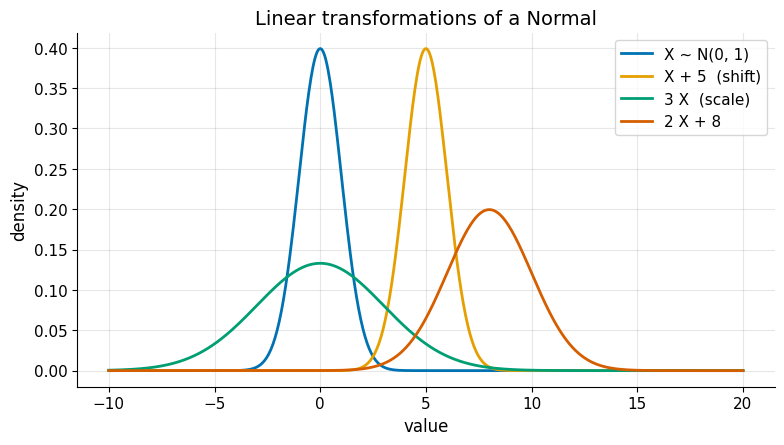

In [2]:
x_axis = np.linspace(-10, 20, 600)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(x_axis, stats.norm(0, 1).pdf(x_axis), color=COLORS[0], linewidth=2, label="X ~ N(0, 1)")
ax.plot(x_axis, stats.norm(5, 1).pdf(x_axis), color=COLORS[1], linewidth=2, label="X + 5  (shift)")
ax.plot(x_axis, stats.norm(0, 3).pdf(x_axis), color=COLORS[2], linewidth=2, label="3 X  (scale)")
ax.plot(x_axis, stats.norm(8, 2).pdf(x_axis), color=COLORS[3], linewidth=2, label="2 X + 8")
ax.set_title("Linear transformations of a Normal")
ax.set_xlabel("value")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.2 A nonlinear transformation: Y = X squared
The density of Y from the change-of-variables formula (two branches) matches a histogram of squared samples; it is the chi-square with 1 d.f.

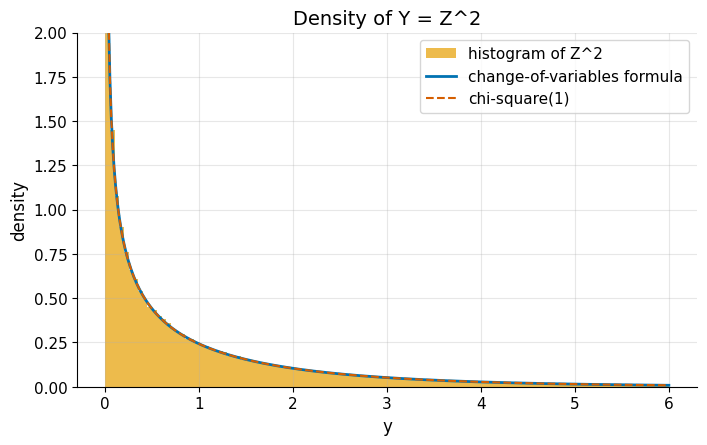

In [3]:
z = rng.normal(size=200_000)
y_samples = z**2
y_axis = np.linspace(0.02, 6, 400)
formula = 2 * stats.norm.pdf(np.sqrt(y_axis)) / (2 * np.sqrt(y_axis))      # sum over the branches x = +-sqrt(y)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(y_samples, bins=120, range=(0, 6), density=True, color=SIM, alpha=0.7, label="histogram of Z^2")
ax.plot(y_axis, formula, color=MAIN, linewidth=2, label="change-of-variables formula")
ax.plot(y_axis, stats.chi2(1).pdf(y_axis), "--", color=HIGHLIGHT, label="chi-square(1)")
ax.set_ylim(0, 2)
ax.set_title("Density of Y = Z^2")
ax.set_xlabel("y")
ax.set_ylabel("density")
ax.legend()
plt.show()
assert np.allclose(formula, stats.chi2(1).pdf(y_axis))

### 7.3 Exp and log: Normal and Lognormal
Exponentiating a Normal gives a skewed Lognormal; taking logs undoes it.

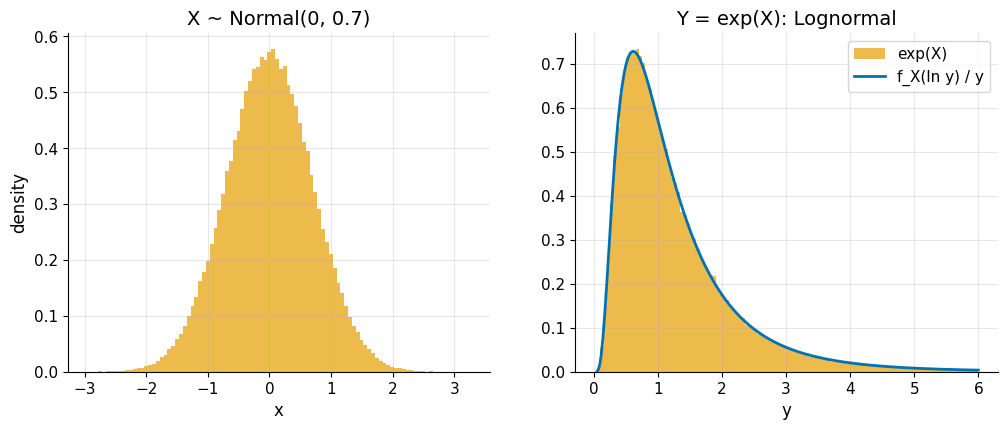

In [4]:
x = rng.normal(0, 0.7, size=200_000)
y = np.exp(x)
fig, (ax_x, ax_y) = plt.subplots(1, 2, figsize=(12, 4.4))
ax_x.hist(x, bins=100, density=True, color=SIM, alpha=0.7)
ax_x.set_title("X ~ Normal(0, 0.7)")
ax_x.set_xlabel("x")
ax_x.set_ylabel("density")
grid = np.linspace(0.05, 6, 400)
ax_y.hist(y, bins=120, range=(0, 6), density=True, color=SIM, alpha=0.7, label="exp(X)")
ax_y.plot(grid, stats.norm(0, 0.7).pdf(np.log(grid)) / grid, color=MAIN, linewidth=2, label="f_X(ln y) / y")
ax_y.set_title("Y = exp(X): Lognormal")
ax_y.set_xlabel("y")
ax_y.legend()
plt.show()

### 7.4 The probability integral transform
Applying a variable's own CDF turns it into a Uniform; applying the quantile function to a Uniform generates the variable.

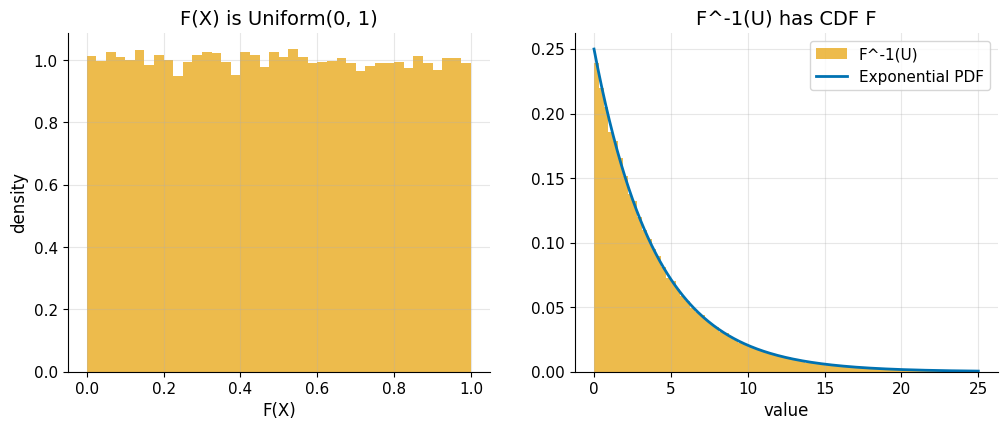

KS tests (large p = consistent): 0.052 0.143


In [5]:
waits = rng.exponential(4, size=100_000)
uniformized = stats.expon(scale=4).cdf(waits)
regenerated = stats.expon(scale=4).ppf(rng.uniform(size=100_000))
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4.4))
ax_a.hist(uniformized, bins=40, density=True, color=SIM, alpha=0.7)
ax_a.set_title("F(X) is Uniform(0, 1)")
ax_a.set_xlabel("F(X)")
ax_a.set_ylabel("density")
ax_b.hist(regenerated, bins=80, range=(0, 25), density=True, color=SIM, alpha=0.7, label="F^-1(U)")
ax_b.plot(np.linspace(0, 25, 300), stats.expon(scale=4).pdf(np.linspace(0, 25, 300)), color=MAIN, linewidth=2, label="Exponential PDF")
ax_b.set_title("F^-1(U) has CDF F")
ax_b.set_xlabel("value")
ax_b.legend()
plt.show()
print("KS tests (large p = consistent):", round(stats.kstest(uniformized, "uniform").pvalue, 3), round(stats.kstest(regenerated, stats.expon(scale=4).cdf).pvalue, 3))

## 8. 3D visuals

### 8.1 Static: density of Y = X squared over (y, mu), X ~ N(mu, 1)
The density of the squared variable moves from a spike at 0 (mu = 0) to a hump near mu squared.

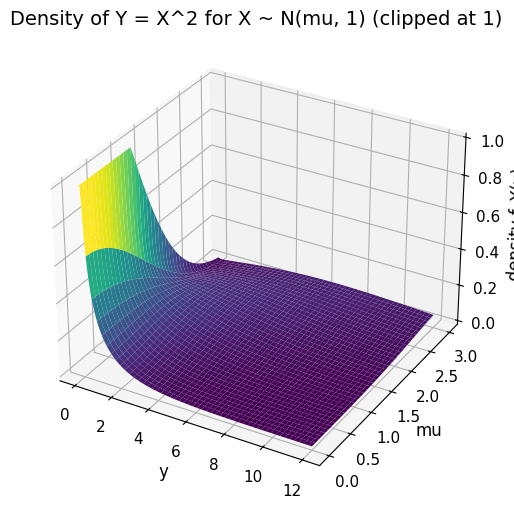

In [6]:
y_values = np.linspace(0.05, 12, 200)
mu_values = np.linspace(0, 3, 40)
Y, M = np.meshgrid(y_values, mu_values)
Z = (stats.norm.pdf(np.sqrt(Y), M, 1) + stats.norm.pdf(-np.sqrt(Y), M, 1)) / (2 * np.sqrt(Y))     # both branches
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Y, M, np.minimum(Z, 1.0), cmap="viridis", edgecolor="none")
ax.set_title("Density of Y = X^2 for X ~ N(mu, 1) (clipped at 1)")
ax.set_xlabel("y")
ax.set_ylabel("mu")
ax.set_zlabel("density f_Y(y)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the Lognormal density over (y, sigma) from Y = exp(X)

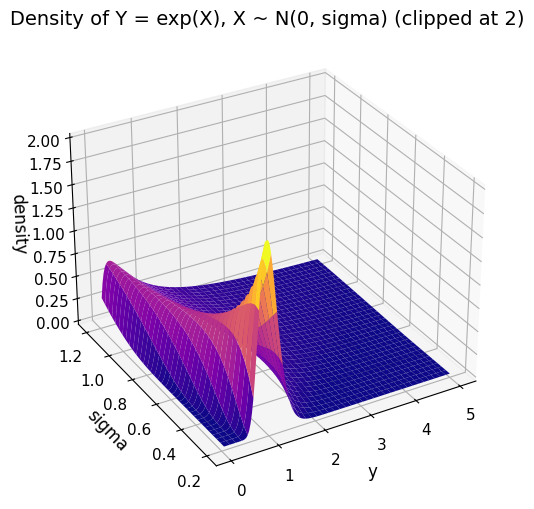

In [7]:
y2 = np.linspace(0.05, 5, 160)
sigma_values = np.linspace(0.2, 1.2, 35)
Y2, S = np.meshgrid(y2, sigma_values)
Z2 = stats.norm.pdf(np.log(Y2), 0, S) / Y2
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Y2, S, np.minimum(Z2, 2), cmap="plasma", edgecolor="none")
ax.set_title("Density of Y = exp(X), X ~ N(0, sigma) (clipped at 2)")
ax.set_xlabel("y")
ax.set_ylabel("sigma")
ax.set_zlabel("density")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version of 8.1

In [8]:
fig = go.Figure(go.Surface(x=y_values, y=mu_values, z=np.minimum(Z, 1.0), colorscale="Viridis"))
fig.update_layout(title="Density of Y = X^2 for X ~ N(mu, 1) (clipped at 1)", width=750, height=550,
                  scene=dict(xaxis_title="y", yaxis_title="mu", zaxis_title="density f_Y(y)"))
fig.show()

## 9. Simulation vs theory

### 9.1 E[g(X)] versus g(E[X])
For Z standard Normal and g(x) = x^2: E[g(Z)] = 1 but g(E[Z]) = 0.

In [9]:
z = rng.normal(size=1_000_000)
print(f"E[Z^2] = {np.mean(z**2):.4f} (theory 1) vs (E[Z])^2 = {np.mean(z) ** 2:.6f} (theory 0)")
print(f"median of exp(X) = {np.median(np.exp(x)):.4f} vs exp(median of X) = {np.exp(np.median(x)):.4f}  (quantiles are preserved)")
print(f"mean of exp(X) = {np.mean(np.exp(x)):.4f} vs exp(mean of X) = {np.exp(np.mean(x)):.4f}  (means are not; theory exp(sigma^2/2) = {np.exp(0.7**2 / 2):.4f})")

E[Z^2] = 0.9995 (theory 1) vs (E[Z])^2 = 0.000003 (theory 0)
median of exp(X) = 1.0004 vs exp(median of X) = 1.0004  (quantiles are preserved)
mean of exp(X) = 1.2774 vs exp(mean of X) = 1.0006  (means are not; theory exp(sigma^2/2) = 1.2776)


### 9.2 Running mean of g(X)

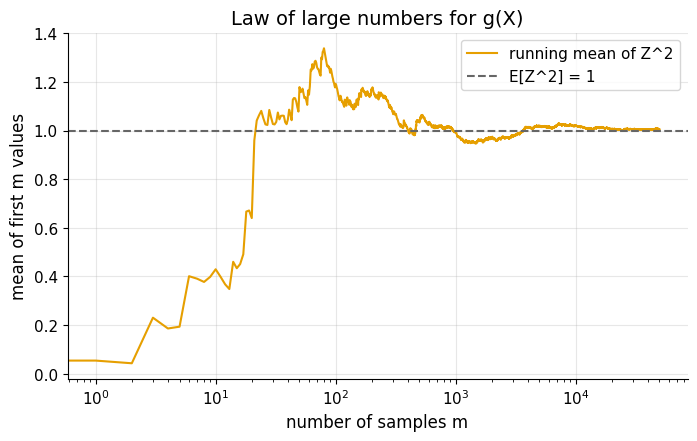

In [10]:
running = np.cumsum(z[:50_000] ** 2) / np.arange(1, 50_001)
fig, ax = plt.subplots()
ax.plot(running, color=SIM, label="running mean of Z^2")
ax.axhline(1, color=NEUTRAL, linestyle="--", label="E[Z^2] = 1")
ax.set_xscale("log")
ax.set_title("Law of large numbers for g(X)")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m values")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

`loc` and `scale` are linear transformations built into every `scipy` distribution, and `expect` computes E[g(X)] numerically.

In [11]:
base = stats.norm(0, 1)
shifted = stats.norm(loc=8, scale=2)                       # the law of 2 Z + 8
print("pdf of 2Z+8 at 9 equals pdf_Z((9 - 8) / 2) / 2 :", round(shifted.pdf(9), 5), round(base.pdf(0.5) / 2, 5))
print("E[Z^2] by expect                              :", round(base.expect(lambda t: t**2), 5))
print("E[exp(Z)] by expect (theory exp(0.5))         :", round(base.expect(np.exp, lb=-12, ub=12), 5), round(np.exp(0.5), 5))
print("lognorm(s, scale=exp(mu)) is exp of a Normal   :", round(stats.lognorm(0.7).median(), 4), "= exp(0) = 1")
print("chi2(1) = Z^2: sf(3.84) =", round(stats.chi2(1).sf(3.84), 4), " P(|Z| > 1.96) =", round(2 * base.sf(1.96), 4))

pdf of 2Z+8 at 9 equals pdf_Z((9 - 8) / 2) / 2 : 0.17603 0.17603
E[Z^2] by expect                              : 1.0
E[exp(Z)] by expect (theory exp(0.5))         : 1.64872 1.64872
lognorm(s, scale=exp(mu)) is exp of a Normal   : 1.0 = exp(0) = 1
chi2(1) = Z^2: sf(3.84) = 0.05  P(|Z| > 1.96) = 0.05


## 11. Real-world worked example: sensor voltage and power

**Scenario (illustrative numbers).** A sensor's voltage $V$ (volts) is Normal with mean **5** and SD **0.2**. It drives a resistor of $R=10\ \Omega$, dissipating power $P=V^2/R$ watts.

**Questions**
1. What is $P(P>2.6)$ (the power limit)?
2. What is the **mean power**? Compare with the power at the mean voltage.
3. What is the **density of the power** $P$?

### 11.1 By hand
**Q1.** $P>2.6\iff V^2>26\iff|V|>\sqrt{26}=5.099$. Practically $V>5.099$ (the other branch $V<-5.099$ has negligible probability). $z=\frac{5.099-5}{0.2}=0.495$, so $P(P>2.6)=1-\Phi(0.495)=0.3103$.

**Q2.** $E[P]=\frac{E[V^2]}{R}=\frac{\mathrm{Var}(V)+E[V]^2}{10}=\frac{0.04+25}{10}=2.504$ W, while the power at the mean voltage is $5^2/10=2.5$ W. The mean of the function is larger (Jensen's inequality, since $x^2$ is convex).

**Q3.** $V=\pm\sqrt{10p}$ gives two branches; $|dv/dp|=\frac{10}{2\sqrt{10p}}=\frac{\sqrt{10}}{2\sqrt p}$, so $f_P(p)=\frac{\sqrt{10}}{2\sqrt p}\Big[f_V(\sqrt{10p})+f_V(-\sqrt{10p})\Big]$ for $p>0$.

In [12]:
import math

mean_v, sd_v, resistance = 5.0, 0.2, 10.0

def standard_normal_cdf(z_value):
    return 0.5 * (1 + math.erf(z_value / math.sqrt(2)))

threshold_v = math.sqrt(2.6 * resistance)
p_over_hand = (1 - standard_normal_cdf((threshold_v - mean_v) / sd_v)) + standard_normal_cdf((-threshold_v - mean_v) / sd_v)
mean_power_hand = (sd_v**2 + mean_v**2) / resistance
power_at_mean_hand = mean_v**2 / resistance
print(f"threshold voltage {threshold_v:.4f}; P(P > 2.6) = {p_over_hand:.4f}; E[P] = {mean_power_hand:.4f}; power at the mean voltage = {power_at_mean_hand:.4f}")

threshold voltage 5.0990; P(P > 2.6) = 0.3103; E[P] = 2.5040; power at the mean voltage = 2.5000


### 11.2 In code with `scipy`, and the asserts
We check the density by integrating it and by taking E[P] numerically with `expect`.

In [13]:
voltage = stats.norm(mean_v, sd_v)
power_density = lambda p: math.sqrt(10) / (2 * np.sqrt(p)) * (voltage.pdf(np.sqrt(10 * p)) + voltage.pdf(-np.sqrt(10 * p)))

p_values = np.linspace(1e-6, 6, 400_001)
density_values = power_density(p_values)
total_area = np.trapezoid(density_values, p_values)
p_over_code = np.trapezoid(density_values[p_values > 2.6], p_values[p_values > 2.6])
mean_power_code = voltage.expect(lambda v: v**2 / resistance)

assert np.isclose(total_area, 1.0, atol=1e-4)
assert np.isclose(p_over_hand, p_over_code, atol=1e-4)
assert np.isclose(mean_power_hand, mean_power_code)
print(f"area under f_P = {total_area:.5f}; P(P > 2.6) from the density = {p_over_code:.4f}; E[P] = {mean_power_code:.4f}")

area under f_P = 1.00000; P(P > 2.6) from the density = 0.3102; E[P] = 2.5040


### 11.3 Verify by simulation

In [14]:
volts = rng.normal(mean_v, sd_v, size=1_000_000)
watts = volts**2 / resistance
print(f"P(P > 2.6): exact {p_over_hand:.4f}, simulated {np.mean(watts > 2.6):.4f}")
print(f"E[P]: exact {mean_power_hand:.4f}, simulated {watts.mean():.4f}; SD of P: {watts.std():.4f}")
assert abs(np.mean(watts > 2.6) - p_over_hand) < 0.003
assert abs(watts.mean() - mean_power_hand) < 0.002

P(P > 2.6): exact 0.3103, simulated 0.3108
E[P]: exact 2.5040, simulated 2.5042; SD of P: 0.2000


### 11.4 Plots

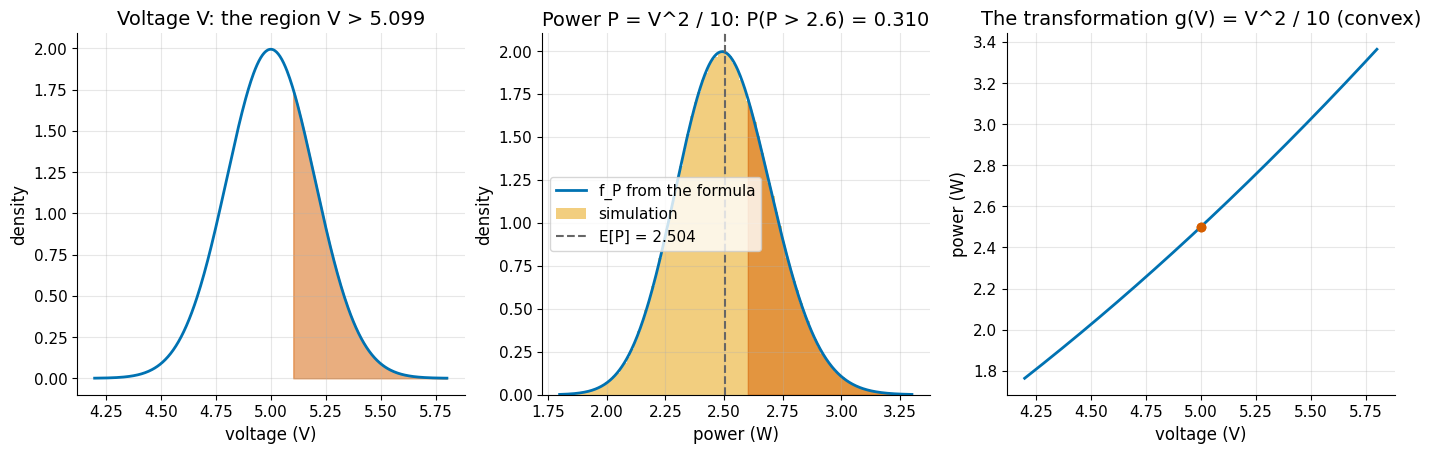

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))
v_axis = np.linspace(4.2, 5.8, 400)
axes[0].plot(v_axis, voltage.pdf(v_axis), color=MAIN, linewidth=2)
axes[0].fill_between(v_axis[v_axis > threshold_v], voltage.pdf(v_axis[v_axis > threshold_v]), color=HIGHLIGHT, alpha=0.5)
axes[0].set_title("Voltage V: the region V > 5.099")
axes[0].set_xlabel("voltage (V)")
axes[0].set_ylabel("density")

p_axis = np.linspace(1.8, 3.3, 600)
axes[1].plot(p_axis, power_density(p_axis), color=MAIN, linewidth=2, label="f_P from the formula")
axes[1].hist(watts, bins=100, range=(1.8, 3.3), density=True, color=SIM, alpha=0.5, label="simulation")
axes[1].fill_between(p_axis[p_axis > 2.6], power_density(p_axis[p_axis > 2.6]), color=HIGHLIGHT, alpha=0.5)
axes[1].axvline(mean_power_hand, color=NEUTRAL, linestyle="--", label="E[P] = 2.504")
axes[1].set_title(f"Power P = V^2 / 10: P(P > 2.6) = {p_over_hand:.3f}")
axes[1].set_xlabel("power (W)")
axes[1].set_ylabel("density")
axes[1].legend()

axes[2].plot(v_axis, v_axis**2 / resistance, color=MAIN, linewidth=2)
axes[2].plot([5, 5], [2.5, 2.5], "o", color=HIGHLIGHT)
axes[2].set_title("The transformation g(V) = V^2 / 10 (convex)")
axes[2].set_xlabel("voltage (V)")
axes[2].set_ylabel("power (W)")
plt.show()

### 11.5 Interpretation and decision
- The power exceeds the **2.6 W limit about 31 % of the time**, although the nominal power (2.5 W) is below the limit: the voltage noise is amplified by the square.
- The **mean power is 2.504 W**, slightly above the power at the mean voltage (2.5 W): a nonlinear function does not commute with the mean.
- **Decision:** a 2.6 W rating is too tight; a rating of about 3.0 W (voltage 5.48 V, 2.4 SD above the mean) would be exceeded less than 1 % of the time. Always propagate the full distribution through nonlinear formulas.

### 11.6 Extra example: temperature and z-scores (linear transformations)
Afternoon temperature is $C\sim N(20,3^2)$ degrees Celsius. In Fahrenheit, $F=1.8C+32$. What are the distribution of $F$, $P(F>77)$ and the z-score of 77 F?

In [16]:
mean_f, sd_f = 1.8 * 20 + 32, 1.8 * 3
p_hot_hand = 1 - standard_normal_cdf((25 - 20) / 3)                    # F > 77 is the same event as C > 25
z_score_hand = (77 - mean_f) / sd_f
temperature_f = stats.norm(mean_f, sd_f)
assert np.isclose(p_hot_hand, temperature_f.sf(77))
assert np.isclose(z_score_hand, (25 - 20) / 3)                         # z-scores are unit free
simulated_f = 1.8 * rng.normal(20, 3, size=500_000) + 32
print(f"F ~ N({mean_f}, {sd_f:.1f}^2); P(F > 77) = {p_hot_hand:.4f} (simulated {np.mean(simulated_f > 77):.4f}); z-score of 77 F = {z_score_hand:.3f} = z-score of 25 C")

F ~ N(68.0, 5.4^2); P(F > 77) = 0.0478 (simulated 0.0478); z-score of 77 F = 1.667 = z-score of 25 C


**Interpretation.** F is Normal with mean 68 and SD 5.4. The probability of a day above 77 F (25 C) is **4.8 %** whichever scale we use; the **z-score (1.67) is the same in both units**: standardizing removes the unit. This is why z-scores allow comparing scores from different exams or measurements on different scales.

## 12. Where it is used

### Statistics
- Deriving sampling distributions (chi-square from squared Normals, t from ratios), the delta method, variance-stabilizing and log transformations.

### Data science
- **Feature engineering:** log, Box-Cox and z-score transforms; unit conversions; propagating uncertainty through formulas (error propagation).

### ML and AI
- **Change of variables** in normalizing flows and VAEs; **reparameterization** ($z=\mu+\sigma\varepsilon$); inverse-transform and Box-Muller sampling; standardizing inputs.

## 13. Common pitfalls and misconceptions

- **E[g(X)] is not g(E[X])** unless g is linear.
- **Forgetting the Jacobian** |dx/dy| when transforming a density (the area would not be 1).
- **Non-monotone maps need all branches** (both x = +sqrt(y) and x = -sqrt(y)).
- **Variance scales with a squared:** Var(aX + b) = a^2 Var(X).
- **Quantiles transform, means do not:** the median of exp(X) is exp(median of X); the mean is not.
- **Transforming the data transforms the question:** a model for log(price) predicts the median price, not the mean.

## 14. Exercises

1. $X\sim N(10,4)$ (variance 4). Find the distribution of $Y=3X-5$ and $P(Y>30)$.
2. $X\sim\text{Uniform}(0,1)$ and $Y=-\ln X$. Find $f_Y$ (use $g^{-1}(y)=e^{-y}$).
3. $X\sim\text{Uniform}(0,2)$ and $Y=X^2$. Find $f_Y$ and $E[Y]$.
4. A price is Lognormal with $\ln P\sim N(3,0.5^2)$. What is the median price, and is the mean larger or smaller?
5. (Harder) Show that if $X$ has CDF $F$ then $1-F(X)$ is also Uniform(0,1).

Solutions are at the end.

## 15. Summary table

| Transformation | Result |
|---|---|
| Y = aX + b | f_Y(y) = f_X((y-b)/a) / abs(a); Normal stays Normal |
| Y = (X - mu)/sigma | mean 0, variance 1 (z-score) |
| Y = X^2, X standard Normal | chi-square(1) |
| Y = exp(X), X Normal | Lognormal |
| Y = F(X) | Uniform(0, 1) |
| Y = F^-1(U) | CDF F (inverse transform sampling) |
| general monotone g | f_Y(y) = f_X(g^-1(y)) abs(dg^-1/dy) |

## Solutions

In [17]:
y1 = stats.norm(3 * 10 - 5, 3 * 2)
print("1: Y ~ N(25, 36); P(Y > 30) =", round(y1.sf(30), 4))
print("2: f_Y(y) = exp(-y): Exponential(1); KS p-value of -ln U:", round(stats.kstest(-np.log(rng.uniform(size=50_000)), "expon").pvalue, 3))
u2 = rng.uniform(0, 2, size=1_000_000)
print("3: f_Y(y) = 1 / (4 sqrt(y)) on (0, 4); E[Y] = 4/3 =", round(4 / 3, 4), " simulated", round(np.mean(u2**2), 4))
print("4: median =", round(math.exp(3), 3), " mean =", round(math.exp(3 + 0.5**2 / 2), 3), "(larger)")
f5 = 1 - stats.expon(scale=2).cdf(rng.exponential(2, size=100_000))
print("5: KS p-value of 1 - F(X) against Uniform:", round(stats.kstest(f5, "uniform").pvalue, 3))

1: Y ~ N(25, 36); P(Y > 30) = 0.2023
2: f_Y(y) = exp(-y): Exponential(1); KS p-value of -ln U: 0.944
3: f_Y(y) = 1 / (4 sqrt(y)) on (0, 4); E[Y] = 4/3 = 1.3333  simulated 1.3328
4: median = 20.086  mean = 22.76 (larger)
5: KS p-value of 1 - F(X) against Uniform: 0.63


**1.** $Y\sim N(3\cdot10-5,\ 9\cdot4)=N(25,36)$; $P(Y>30)=1-\Phi(5/6)=0.2023$.

**2.** $f_Y(y)=f_X(e^{-y})\,|{-e^{-y}}|=e^{-y}$ for $y>0$: Exponential(1).

**3.** $f_X=\frac12$ on $(0,2)$; $x=\sqrt y$, $|dx/dy|=\frac1{2\sqrt y}$, so $f_Y(y)=\frac1{4\sqrt y}$ on $(0,4)$; $E[Y]=E[X^2]=\int_0^2\frac{x^2}2dx=\frac43$.

**4.** Median $e^3=20.09$; mean $e^{3+0.125}=22.76$ is larger (right-skewed).

**5.** $1-F(X)=1-U$ where $U=F(X)$ is Uniform; and $1-U$ is Uniform too.